In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.metrics import precision_score, recall_score
from pathlib import Path
from xgboost import XGBClassifier

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_recall_curve,
    classification_report,
    ConfusionMatrixDisplay
)

sns.set_theme(style="whitegrid")

In [26]:
df = pd.read_csv("../data/raw/flights.csv")
df = df.dropna(subset=["arr_delay"]).copy()

df["delayed"] = (df["arr_delay"] >= 15).astype(int)

df["scheduled_datetime"] = (
    pd.to_datetime(df["time_hour"]) +
    pd.to_timedelta(df["minute"], unit="m")
)

df["day_of_week"] = df["scheduled_datetime"].dt.dayofweek
df["day_of_year"] = df["scheduled_datetime"].dt.dayofyear

df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24)
df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24)
df["dow_sin"] = np.sin(2 * np.pi * df["day_of_week"] / 7)
df["dow_cos"] = np.cos(2 * np.pi * df["day_of_week"] / 7)
df["day_of_year_sin"] = np.sin(2 * np.pi * df["day_of_year"] / 365.25)
df["day_of_year_cos"] = np.cos(2 * np.pi * df["day_of_year"] / 365.25)

feature_cols = [
    "month", "day", "hour", "minute", "day_of_week", "day_of_year",
    "hour_sin", "hour_cos", "dow_sin", "dow_cos",
    "day_of_year_sin", "day_of_year_cos", "distance",
    "carrier", "origin", "dest"
]

categorical_features = ["carrier", "origin", "dest"]
numeric_features = [
    c for c in feature_cols if c not in categorical_features
]

df = df.sort_values("scheduled_datetime").reset_index(drop=True)

X = df[feature_cols]
y = df["delayed"]

n = len(df)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

X_train, y_train = X.iloc[:train_end], y.iloc[:train_end]
X_val, y_val = X.iloc[train_end:val_end], y.iloc[train_end:val_end]
X_test, y_test = X.iloc[val_end:], y.iloc[val_end:]

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)
print("Train delay rate:", round(y_train.mean() * 100, 2), "%")
print("Validation delay rate:", round(y_val.mean() * 100, 2), "%")
print("Test delay rate:", round(y_test.mean() * 100, 2), "%")

Training: (229142, 16)
Validation: (49102, 16)
Testing: (49102, 16)
Train delay rate: 25.94 %
Validation delay rate: 15.39 %
Test delay rate: 26.69 %


/var/folders/42/1195kj1s5cnfdl1h85ykvth40000gn/T/ipykernel_62320/3227636847.py:11: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["day_of_week"] = df["scheduled_datetime"].dt.dayofweek
/var/folders/42/1195kj1s5cnfdl1h85ykvth40000gn/T/ipykernel_62320/3227636847.py:12: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  df["day_of_year"] = df["scheduled_datetime"].dt.dayofyear


In [27]:
preprocessor = ColumnTransformer([
    ("numeric", "passthrough", numeric_features),
    ("categorical", OneHotEncoder(handle_unknown="ignore"),
     categorical_features)
])

xgb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=400,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=1.0,
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        n_jobs=-1,
        random_state=42
    ))
])

print("XGBoost pipeline created.")

XGBoost pipeline created.


In [28]:
xgb_model.fit(X_train, y_train)

val_probs = xgb_model.predict_proba(X_val)[:, 1]

print("Validation PR AUC:",
      round(average_precision_score(y_val, val_probs), 4))

print("Validation ROC AUC:",
      round(roc_auc_score(y_val, val_probs), 4))

Validation PR AUC: 0.2405
Validation ROC AUC: 0.6371


In [29]:
precision, recall, thresholds = precision_recall_curve(
    y_val, val_probs
)

target_precision = 0.60
valid = np.where(precision[:-1] >= target_precision)[0]

if len(valid) > 0:
    best_idx = valid[np.argmax(recall[valid])]
else:
    best_idx = np.argmax(precision[:-1])

selected_threshold = thresholds[best_idx]

print("Selected threshold:", round(selected_threshold, 4))
print("Validation precision:", round(precision[best_idx], 4))
print("Validation recall:", round(recall[best_idx], 4))

Selected threshold: 0.8664
Validation precision: 0.6
Validation recall: 0.0016


Test PR AUC: 0.3338
Test ROC AUC: 0.5985

Classification report:
              precision    recall  f1-score   support

 Not delayed       0.78      0.64      0.70     35996
     Delayed       0.34      0.51      0.40     13106

    accuracy                           0.60     49102
   macro avg       0.56      0.57      0.55     49102
weighted avg       0.66      0.60      0.62     49102



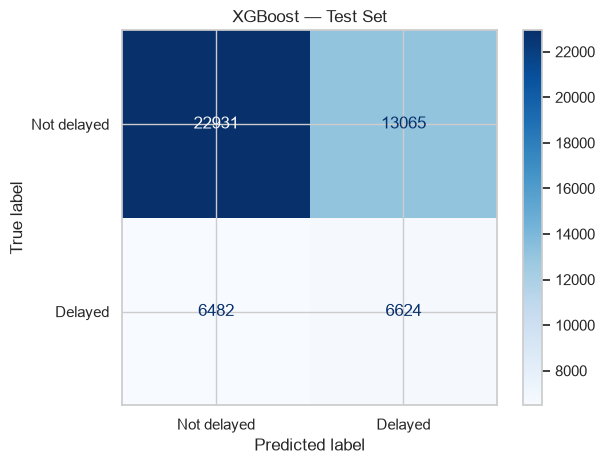

In [30]:
test_probs = xgb_model.predict_proba(X_test)[:, 1]
selected_threshold = 0.3
test_preds = (test_probs >= selected_threshold).astype(int)

print("Test PR AUC:",
      round(average_precision_score(y_test, test_probs), 4))

print("Test ROC AUC:",
      round(roc_auc_score(y_test, test_probs), 4))

print("\nClassification report:")
print(classification_report(
    y_test, test_preds,
    target_names=["Not delayed", "Delayed"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test, test_preds,
    display_labels=["Not delayed", "Delayed"],
    cmap="Blues"
)
plt.title("XGBoost — Test Set")
plt.tight_layout()
plt.show()

,feature,importance
18,categorical__carrier_EV,0.059785
2,numeric__hour,0.045157
11,numeric__day_of_year_cos,0.030859
6,numeric__hour_sin,0.025277
17,categorical__carrier_DL,0.023202
9,numeric__dow_cos,0.022126
43,categorical__dest_BOS,0.021906
0,numeric__month,0.021391
10,numeric__day_of_year_sin,0.019685
5,numeric__day_of_year,0.018869


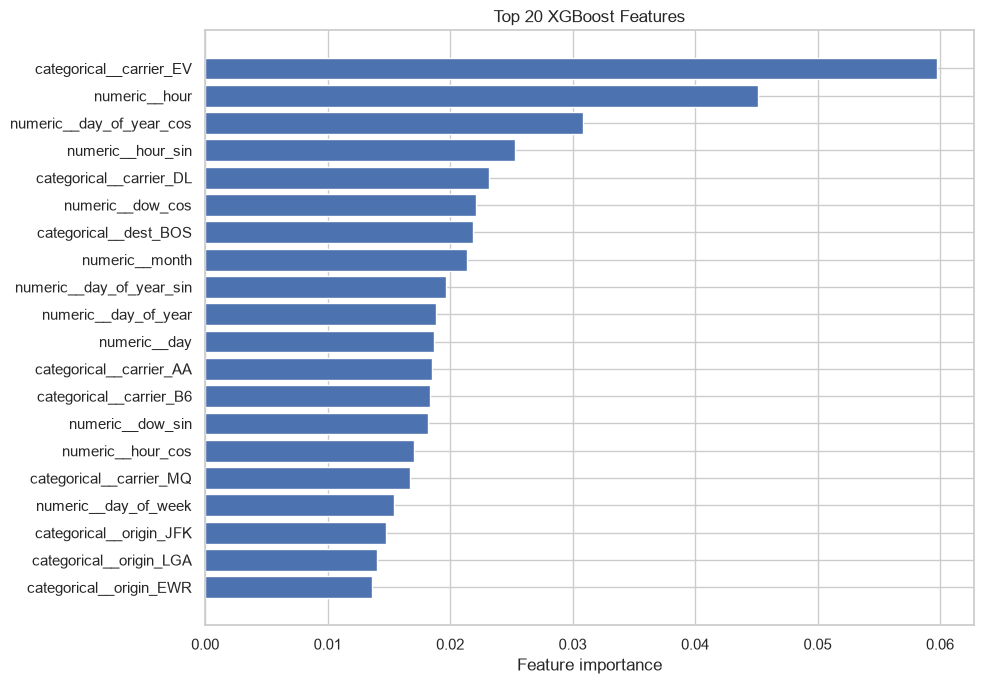

In [31]:
feature_names = (
    xgb_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

importances = xgb_model.named_steps["classifier"].feature_importances_

importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": importances
}).sort_values("importance", ascending=False)

display(importance_df.head(20))

top_features = importance_df.head(20).sort_values("importance")

plt.figure(figsize=(10, 7))
plt.barh(top_features["feature"], top_features["importance"])
plt.title("Top 20 XGBoost Features")
plt.xlabel("Feature importance")
plt.tight_layout()
plt.show()

In [32]:
Path("../models").mkdir(parents=True, exist_ok=True)

joblib.dump(
    {
        "model": xgb_model,
        "threshold": selected_threshold,
        "feature_columns": feature_cols
    },
    "../models/xgboost_model.joblib"
)

print("XGBoost model saved successfully.")

XGBoost model saved successfully.


In [33]:
for threshold in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, selected_threshold]:
    preds = (val_probs >= threshold).astype(int)

    print(
        f"Threshold: {threshold:.4f} | "
        f"Precision: {precision_score(y_val, preds, zero_division=0):.3f} | "
        f"Recall: {recall_score(y_val, preds, zero_division=0):.3f}"
    )

Threshold: 0.2000 | Precision: 0.200 | Recall: 0.703
Threshold: 0.3000 | Precision: 0.218 | Recall: 0.564
Threshold: 0.4000 | Precision: 0.236 | Recall: 0.428
Threshold: 0.5000 | Precision: 0.256 | Recall: 0.290
Threshold: 0.6000 | Precision: 0.290 | Recall: 0.179
Threshold: 0.7000 | Precision: 0.333 | Recall: 0.083
Threshold: 0.3000 | Precision: 0.218 | Recall: 0.564
